# DMD in 15 lines of NumPy: read it, run it, break it

**Dynamic mode decomposition (DMD)** learns the characteristic *modes* of a time series (patterns that each decay, grow or oscillate on their own) and uses them to extrapolate. The whole method fits in a short NumPy function. This notebook takes that function apart:

1. **Read it** line by line: what each line does mathematically, and the shape of every array.
2. **Run it** on a toy system whose exact answer we know, so that we can *check* the output.
3. **Break it**, on purpose, to understand the four practical rules of thumb that come with the method:

| Remark | Experiment |
|---|---|
| **Choosing $r$** (number of singular values kept) | too few modes lose dynamics; too many fit the noise and can make predictions blow up |
| **The dynamics must be (approximately) linear** | a pendulum: DMD works for small swings and degrades for large ones |
| **Sampling** | a rotating vector sampled too slowly returns a wrong (aliased) frequency |
| **Cost** | timings, and why we never build the $N\times N$ matrix |

You should know basic Python/NumPy, and have met eigenvalues and the SVD (a short reminder appears where needed). If you want the full derivation of DMD, see the companion tutorial *Dynamic Mode Decomposition (DMD)*; here we concentrate on **the code and on how to use it wisely**.

**How to run:** run the cells from top to bottom on a normal CPU runtime (everything takes seconds; no installation needed). Cells marked **Your turn** invite you to change a value and re-run.

## 0. Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("numpy", np.__version__)

numpy 2.4.6


---
# 1. The code

The data are stored in an array `V` of shape $N\times n$ whose **columns are the snapshots** $v_1,\dots,v_n$ (taken at times $t_j=(j-1)\,\Delta t$). Here is the complete implementation:

In [2]:
def dmd(V, r):
    X, Y = V[:, :-1], V[:, 1:]                               # shifted data matrices
    U, s, Vh = np.linalg.svd(X, full_matrices=False)         # X = U diag(s) Vh
    U, s, Vh = U[:, :r], s[:r], Vh[:r, :]                    # keep r singular values
    A_tilde = U.conj().T @ Y @ Vh.conj().T @ np.diag(1/s)   # r x r matrix
    lam, W = np.linalg.eig(A_tilde)                          # eigenvalues, eigenvectors
    Gamma = Y @ Vh.conj().T @ np.diag(1/s) @ W / lam         # exact DMD modes (columns)
    c = np.linalg.lstsq(Gamma, V[:, 0], rcond=None)[0]       # amplitudes (overlap formula)
    return lam, Gamma, c

def predict(lam, Gamma, c, j):                               # state at time t_j = (j-1)*dt
    return (Gamma @ (c * lam**(j - 1))).real                 # real part for real data

# mu = np.log(lam)/dt gives the decay rates (real part) and frequencies (imaginary part)

### Reading it line by line

Let $N$ be the number of entries per snapshot, $n$ the number of snapshots, $r$ the number of kept singular values.

| Line | Mathematics | Shapes |
|---|---|---|
| `X, Y = V[:, :-1], V[:, 1:]` | $X=[v_1\cdots v_{n-1}]$, $Y=[v_2\cdots v_n]$: the same movie shifted by one step. The model is $Y\approx AX$ for a propagator $A$. | $X,Y$: $N\times(n-1)$ |
| `np.linalg.svd(X, full_matrices=False)` | $X=U\Sigma V^T$ (reduced SVD). `Vh` is $V^T$ and `s` holds the diagonal of $\Sigma$. | $U$: $N\times m$, `s`: $m$, `Vh`: $m\times(n-1)$, $m=\min(N,n-1)$ |
| `U[:, :r], s[:r], Vh[:r, :]` | truncation: keep the $r$ largest singular values | $U$: $N\times r$, `s`: $r$, `Vh`: $r\times(n-1)$ |
| `A_tilde = U.conj().T @ Y @ Vh.conj().T @ np.diag(1/s)` | $\tilde A=U^\dagger\,Y\,V\,\Sigma^{-1}$: the propagator in the coordinates of the $r$ dominant patterns. (`Vh.conj().T` is $V$.) | $r\times r$ |
| `lam, W = np.linalg.eig(A_tilde)` | $\tilde A\,W_k=\lambda_kW_k$. The $\lambda_k$ are eigenvalues of the huge propagator $A$. | `lam`: $r$, `W`: $r\times r$ |
| `Gamma = Y @ Vh.conj().T @ np.diag(1/s) @ W / lam` | $\Gamma_k=\lambda_k^{-1}\,Y V\Sigma^{-1}W_k$: the **exact DMD modes**. The division by `lam` acts column by column. | $N\times r$ |
| `c = np.linalg.lstsq(Gamma, V[:, 0], rcond=None)[0]` | amplitudes: least-squares solution of $\Gamma c\approx v_1$, equal to $c=(\Gamma^\dagger\Gamma)^{-1}\Gamma^\dagger v_1$ (the overlap-matrix formula; the modes are not orthogonal). | $r$ |
| `predict(...)` | $v_j=\sum_kc_k\lambda_k^{\,j-1}\Gamma_k$: every mode just gets multiplied by its own $\lambda_k$ at each step. `.real` because the imaginary parts cancel for real data. | $N$ |
| `mu = np.log(lam)/dt` | $\mu_k=\ln\lambda_k/\Delta t$: $\mathrm{Re}\,\mu_k$ is the growth ($>0$) / decay ($<0$) rate, $\mathrm{Im}\,\mu_k$ the angular frequency. | $r$ |

Two things worth noticing right away: **we never build the $N\times N$ propagator** (only $\tilde A$, which is $r\times r$), and **`r` must be chosen by you**.

---
# 2. Run it on a system with a known answer

To check the function we need data whose modes we know. We build a *linear* system with $N=100$ "sensors" (points along a line) and three modes: a **decaying oscillation** (a complex-conjugate pair of eigenvalues $0.97\,e^{\pm0.35i}$) and a **pure decay** ($0.85$):
$$v_j=\sum_{k=1}^{3}c_k\,\lambda_k^{\,j-1}\,\Gamma_k ,\qquad \Delta t=0.1 .$$

V_obs shape: (100, 40)
true decay rates / frequencies  Re mu, Im mu: [-0.305 -0.305 -1.625] [ 3.5 -3.5  0. ]


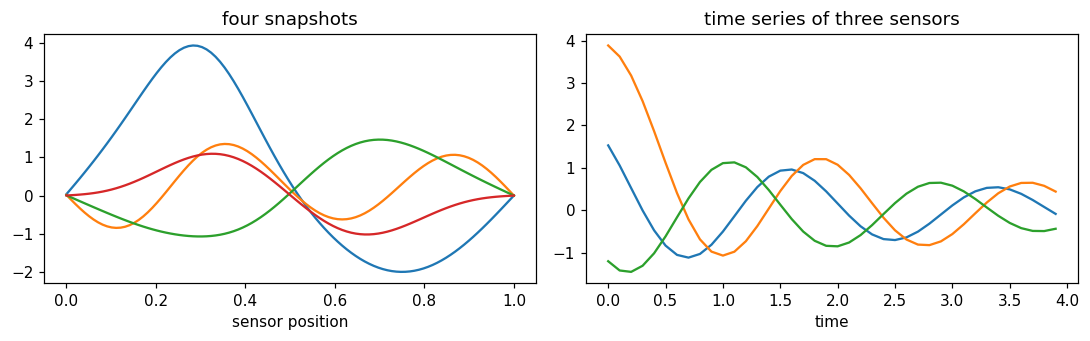

In [3]:
N, dt = 100, 0.1
xgrid = np.linspace(0, 1, N)
shape_osc = np.sin(2*np.pi*xgrid) + 0.5j*np.sin(4*np.pi*xgrid)       # complex shape of the oscillating pair
shape_dec = np.exp(-((xgrid - 0.3)/0.15)**2)                         # shape of the decaying mode

lam_true = np.array([0.97*np.exp(0.35j), 0.97*np.exp(-0.35j), 0.85])
Gam_true = np.stack([shape_osc, shape_osc.conj(), shape_dec.astype(complex)], axis=1)   # N x 3
c_true   = np.array([1.0, 1.0, 2.0], dtype=complex)

def exact_state(j):                       # exact state at time t_j = (j-1)*dt, j = 1, 2, ...
    return (Gam_true @ (c_true * lam_true**(j - 1))).real

n_obs, n_future = 40, 60                  # we "observe" 40 snapshots and will try to predict the next 60
J = np.arange(1, n_obs + n_future + 1)
V_exact = np.stack([exact_state(j) for j in J], axis=1)               # N x 100 (noise-free)
V_obs = V_exact[:, :n_obs]                                            # what we observe: N x 40

print("V_obs shape:", V_obs.shape)
print("true decay rates / frequencies  Re mu, Im mu:",
      (np.log(lam_true)/dt).real.round(3), (np.log(lam_true)/dt).imag.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(xgrid, V_obs[:, [0, 5, 10, 20]]); ax[0].set(xlabel="sensor position", title="four snapshots")
ax[1].plot(np.arange(n_obs)*dt, V_obs[[10, 30, 60], :].T); ax[1].set(xlabel="time", title="time series of three sensors")
plt.tight_layout(); plt.show()

We know that there are exactly **3 modes**, so `r = 3`. Let's call the function and compare with the truth.

In [4]:
lam, Gamma, c = dmd(V_obs, r=3)

mu = np.log(lam) / dt                                             # decay rates and frequencies
order = np.argsort(-mu.imag)                                      # sort for readable output
print("DMD  eigenvalues lambda :", lam[order])
print("true eigenvalues lambda :", lam_true[[0, 2, 1]])
print("DMD  Re(mu) (decay rate):", mu.real[order].round(4), "   Im(mu) (frequency):", mu.imag[order].round(4))
print("true Re(mu)             :", (np.log(lam_true)/dt).real[[0, 2, 1]].round(4),
      "   Im(mu):", (np.log(lam_true)/dt).imag[[0, 2, 1]].round(4))

# Modes are only defined up to a complex scale factor, so compare *directions*: |<G_dmd|G_true>| / (|G_dmd||G_true|)
print("\nmode similarity with the true modes (1.0000 = same direction):")
for k in order:
    kt = np.argmin(abs(lam_true - lam[k]))                        # true mode with the closest eigenvalue
    sim = abs(np.vdot(Gamma[:, k], Gam_true[:, kt])) / (np.linalg.norm(Gamma[:, k]) * np.linalg.norm(Gam_true[:, kt]))
    print(f"  lambda = {lam[k]:.4f}  ->  {sim:.6f}")

pred_err = [np.linalg.norm(predict(lam, Gamma, c, j) - V_exact[:, j-1]) / np.linalg.norm(V_exact[:, j-1]) for j in J]
print(f"\nrelative error: observed window {np.mean(pred_err[:n_obs]):.2e}   prediction (60 steps) {np.mean(pred_err[n_obs:]):.2e}")

DMD  eigenvalues lambda : [0.9112+0.3326j 0.85  +0.j     0.9112-0.3326j]
true eigenvalues lambda : [0.9112+0.3326j 0.85  +0.j     0.9112-0.3326j]
DMD  Re(mu) (decay rate): [-0.3046 -1.6252 -0.3046]    Im(mu) (frequency): [ 3.5  0.  -3.5]
true Re(mu)             : [-0.3046 -1.6252 -0.3046]    Im(mu): [ 3.5  0.  -3.5]

mode similarity with the true modes (1.0000 = same direction):
  lambda = 0.9112+0.3326j  ->  1.000000
  lambda = 0.8500+0.0000j  ->  1.000000
  lambda = 0.9112-0.3326j  ->  1.000000

relative error: observed window 2.77e-15   prediction (60 steps) 1.21e-14


DMD recovered the eigenvalues, the decay rate and the frequency, the *directions* of the modes (their overall scale and phase are arbitrary and absorbed in the amplitudes `c`), and it predicts the next 60 snapshots to rounding error.

### Seeing the shapes
To really trust the line-by-line table, here is the same function with a `print` of every shape (a "verbose" copy), and a numerical check of two claims made in the table.

In [5]:
def dmd_verbose(V, r):
    print("V             :", V.shape)
    X, Y = V[:, :-1], V[:, 1:];                                     print("X, Y          :", X.shape, Y.shape)
    U, s, Vh = np.linalg.svd(X, full_matrices=False);               print("U, s, Vh      :", U.shape, s.shape, Vh.shape)
    U, s, Vh = U[:, :r], s[:r], Vh[:r, :];                          print("after trunc.  :", U.shape, s.shape, Vh.shape)
    A_tilde = U.conj().T @ Y @ Vh.conj().T @ np.diag(1/s);         print("A_tilde       :", A_tilde.shape)
    lam, W = np.linalg.eig(A_tilde);                                print("lam, W        :", lam.shape, W.shape)
    Gamma = Y @ Vh.conj().T @ np.diag(1/s) @ W / lam;               print("Gamma         :", Gamma.shape)
    c = np.linalg.lstsq(Gamma, V[:, 0], rcond=None)[0];             print("c             :", c.shape)
    return lam, Gamma, c

_ = dmd_verbose(V_obs, 3)

# Claim 1: the amplitudes from lstsq equal the overlap-matrix formula  c = (Gamma^H Gamma)^-1 Gamma^H v_1
S = Gamma.conj().T @ Gamma
c_overlap = np.linalg.solve(S, Gamma.conj().T @ V_obs[:, 0])
print("\nlstsq amplitudes == overlap formula:", np.allclose(c, c_overlap))

# Claim 2: each DMD mode is an exact eigenvector of the propagator A = Y X^+ (which we do NOT normally build)
X, Y = V_obs[:, :-1], V_obs[:, 1:]
A_full = Y @ np.linalg.pinv(X)                                   # N x N, built here only for this check
print("max |A Gamma - Gamma lambda| =", np.abs(A_full @ Gamma - Gamma * lam).max())

V             : (100, 40)
X, Y          : (100, 39) (100, 39)
U, s, Vh      : (100, 39) (39,) (39, 39)
after trunc.  : (100, 3) (3,) (3, 39)
A_tilde       : (3, 3)
lam, W        : (3,) (3, 3)
Gamma         : (100, 3)
c             : (3,)

lstsq amplitudes == overlap formula: True
max |A Gamma - Gamma lambda| = 3.0531133177191805e-16


---
# 3. Remark 1: choosing $r$

> *Plot the singular values on a logarithmic scale and look for a gap. Keeping too few modes loses real dynamics; keeping too many fits the noise, and noise modes can have $|\lambda_k|>1$, which makes predictions blow up.*

Real data are noisy. We add random measurement noise to our toy data and look at the singular values of $X$.

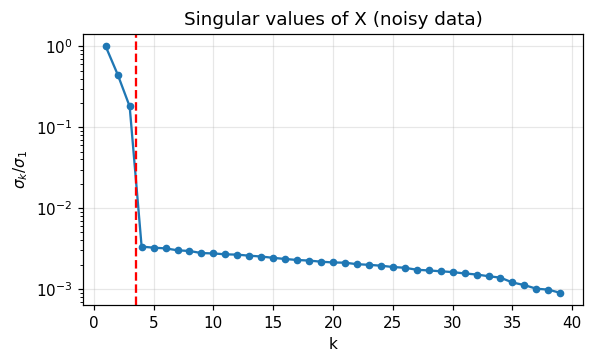

sigma_k/sigma_1, k = 1..6: [1.     0.4494 0.1814 0.0033 0.0032 0.0032]


In [6]:
rng = np.random.default_rng(1)
noise = 0.01                                              # <- Your turn: try 0.0, 0.05, 0.2
V_noisy = V_obs + noise * rng.normal(size=V_obs.shape)

s = np.linalg.svd(V_noisy[:, :-1], compute_uv=False)
plt.figure(figsize=(5.5, 3.4))
plt.semilogy(np.arange(1, len(s) + 1), s / s[0], "o-", ms=4)
plt.axvline(3.5, color="r", ls="--")
plt.xlabel("k"); plt.ylabel(r"$\sigma_k/\sigma_1$"); plt.title("Singular values of X (noisy data)"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("sigma_k/sigma_1, k = 1..6:", s[:6] / s[0])

Three singular values stand out (the signal) and then there is a flat **plateau** at the noise level: the gap tells us $r=3$. Now we try *every* sensible $r$ and measure how well each model predicts the future, **near** the end of the data and **far** from it.

In [7]:
def rel_err(lam, Gamma, c, j):
    return np.linalg.norm(predict(lam, Gamma, c, j) - V_exact[:, j-1]) / np.linalg.norm(V_exact[:, j-1])

print("   r   max|lambda|   error at j=40 (end of data)   j=60 (+20 steps)   j=100 (+60 steps)")
for r in (1, 2, 3, 4, 6, 10, 20, 39):
    l, G, cc = dmd(V_noisy, r)
    print(f"{r:4d}   {abs(l).max():8.3f}          {rel_err(l, G, cc, 40):8.3f}              {rel_err(l, G, cc, 60):8.3f}          {rel_err(l, G, cc, 100):8.3f}")

   r   max|lambda|   error at j=40 (end of data)   j=60 (+20 steps)   j=100 (+60 steps)
   1      0.852             0.988                 1.000             1.000
   2      0.943             0.757                 1.330             1.070
   3      0.970             0.005                 0.007             0.006
   4      0.970             0.005                 0.007             0.007
   6      0.970             0.005                 0.006             0.006
  10      0.970             0.005                 0.008             0.007
  20      0.970             0.005                 0.008             0.010
  39      1.004             0.021                 0.051             0.082


Read the table:

* **$r<3$ (too few):** a real mode is missing; the error is of order one *at every horizon*.
* **$r=3$ (the gap):** small errors that stay small, and $\max|\lambda|\approx0.97$ (the true value).
* **A few more than 3:** barely worse here: extra modes have tiny amplitude.
* **$r=39$ (all the singular values, including the plateau of noise):** the largest $|\lambda|$ exceeds $1$ and **the error grows with the prediction horizon**, because a mode with $|\lambda|>1$ is multiplied by a number larger than 1 at *every* step: $|\lambda|^{j}$ grows exponentially.

Let's look at the eigenvalues for these two choices.

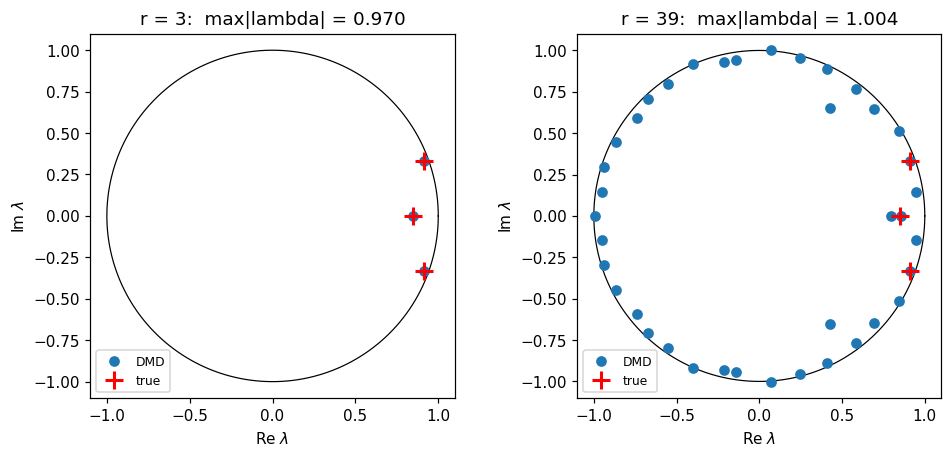

In [8]:
th = np.linspace(0, 2*np.pi, 200)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
for a, r in zip(ax, (3, 39)):
    l, G, cc = dmd(V_noisy, r)
    a.plot(np.cos(th), np.sin(th), "k-", lw=.8)
    a.plot(l.real, l.imag, "o", label="DMD")
    a.plot(lam_true.real, lam_true.imag, "r+", ms=12, mew=2, label="true")
    a.set(title=f"r = {r}:  max|lambda| = {abs(l).max():.3f}", xlabel="Re $\\lambda$", ylabel="Im $\\lambda$", aspect="equal")
    a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

With $r=3$ the three eigenvalues sit on the true ones (red crosses). With $r=39$ many spurious eigenvalues appear, crowding the unit circle, with a few of them slightly outside it (for this noise draw the largest $|\lambda|$ is just above $1$, which is enough for the error to grow with the horizon; with other noise levels or longer horizons the effect can be much larger).

**Your turn.** Change `noise` above (e.g. to $0.05$ and $0.2$) and re-run the three cells: where does the gap in the singular values disappear? What happens to the best choice of $r$?

**Rule of thumb:** put $r$ at the gap, i.e. keep the singular values clearly above the noise plateau. A common automatic rule is to keep those with $\sigma_k>\epsilon\,\sigma_1$ and pick $\epsilon$ just above the noise floor; but always look at the plot.

---
# 4. Remark 2: the dynamics must be (approximately) linear

> *For a first-order kinetic network this is exact. For nonlinear systems DMD finds the best linear approximation of the data, which is usually good for short extrapolations only.*

DMD builds a model $v_{j+1}=Av_j$ with **one fixed matrix**. A good test is a **nonlinear** system: the pendulum, $\ddot\theta=-\sin\theta$. For small swings $\sin\theta\approx\theta$ and the system is linear (a harmonic oscillator with angular frequency 1). For large swings it is not: the period gets longer. The snapshot is $v=(\theta,\dot\theta)$ ($N=2$), sampled every $0.25$ time units. We observe 25 snapshots (about one period) and predict 100 more (about four periods) with an $r=2$ model.

theta0   DMD frequency   |lambda|   relative error at 0, +25, +50, +100 steps beyond the data
  0.1       0.9994      1.0000    [0. 0. 0. 0.]
  1.0       0.9404      0.9999    [0.001 0.03  0.057 0.095]
  2.0       0.7512      1.0041    [0.02  0.231 0.225 0.511]


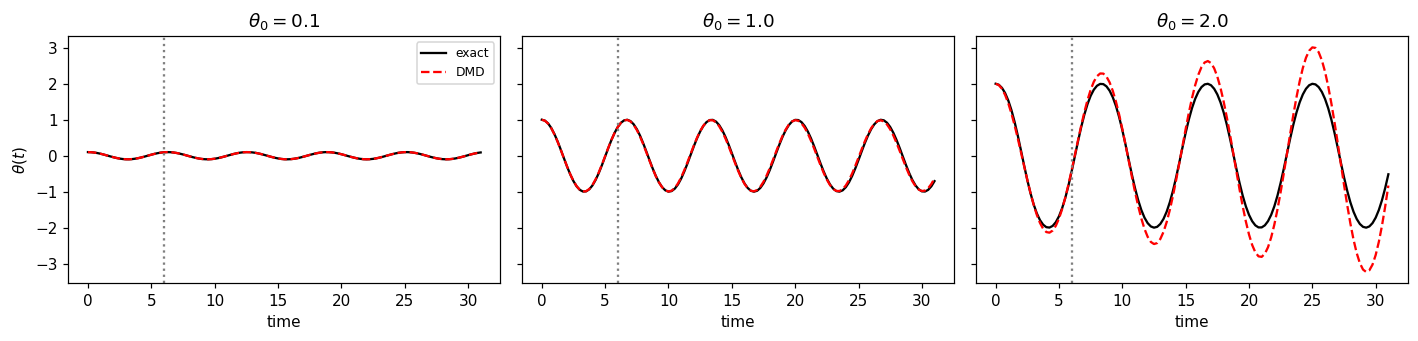

In [9]:
def pendulum(theta0, n, dt=0.25):
    t = np.arange(n) * dt
    sol = solve_ivp(lambda t, y: [y[1], -np.sin(y[0])], [0, t[-1]], [theta0, 0.0], t_eval=t, rtol=1e-10, atol=1e-12)
    return t, sol.y                                      # y has shape (2, n): rows theta, omega

n_obs_p, n_fut_p, dt_p = 25, 100, 0.25
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
print("theta0   DMD frequency   |lambda|   relative error at 0, +25, +50, +100 steps beyond the data")
for a, theta0 in zip(axs, (0.1, 1.0, 2.0)):
    t, Vp = pendulum(theta0, n_obs_p + n_fut_p, dt_p)
    l, G, cc = dmd(Vp[:, :n_obs_p], r=2)
    model = np.stack([predict(l, G, cc, j) for j in range(1, n_obs_p + n_fut_p + 1)], axis=1)
    errs = [np.linalg.norm(model[:, j-1] - Vp[:, j-1]) / np.linalg.norm(Vp[:, j-1]) for j in (n_obs_p, n_obs_p+25, n_obs_p+50, n_obs_p+100)]
    freq = abs(np.angle(l[0])) / dt_p
    print(f" {theta0:4.1f}      {freq:7.4f}      {abs(l[0]):.4f}    {np.round(errs, 3)}")
    a.plot(t, Vp[0], "k-", label="exact")
    a.plot(t, model[0], "r--", label="DMD")
    a.axvline(t[n_obs_p - 1], color="gray", ls=":")
    a.set(title=rf"$\theta_0 = {theta0}$", xlabel="time")
axs[0].set_ylabel(r"$\theta(t)$"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

* For a **small swing** ($\theta_0=0.1$) the pendulum is linear, and DMD is essentially exact at every horizon.
* For **larger swings** DMD finds the best *linear* oscillator for the observed window, with a frequency that differs from the true one. The error is tiny at the end of the data (the model fits the window), but it **grows with the prediction horizon** as the phases drift apart (and, since the fitted $|\lambda|$ is not exactly 1, the predicted amplitude can drift too: see the right panel).

So: DMD is exact for linear dynamics, a good short-term predictor for mildly nonlinear dynamics, and unreliable for long extrapolation of strongly nonlinear dynamics. (Extensions of DMD that use richer sets of observables exist for such cases; see the references.)

**Your turn.** Try `theta0 = 2.8`, a shorter or longer observation window (`n_obs_p`), and a different `dt_p`.

---
# 5. Remark 3: sampling and aliasing

> *The time step $\Delta t$ must be short enough that no mode turns by more than half a period per step; otherwise the frequency $\arg(\lambda_k)/\Delta t$ is ambiguous (aliasing).*

The phase of an eigenvalue is only defined modulo $2\pi$. A mode rotating by an angle $\omega\,\Delta t$ per step is indistinguishable from one rotating by $\omega\,\Delta t-2\pi$, so DMD can only report frequencies with $|\omega|\Delta t<\pi$. Test: a rotating vector $v(t)=(\cos\omega t,\ \sin\omega t)$ with true $\omega=2.5$, sampled with different time steps.

  dt    omega*dt   DMD frequency
  0.5     1.25       2.5000   
  1.0     2.50       2.5000   
  1.2     3.00       2.5000   
  1.5     3.75       1.6888   <-- aliased (omega*dt > pi)
  2.0     5.00       0.6416   <-- aliased (omega*dt > pi)


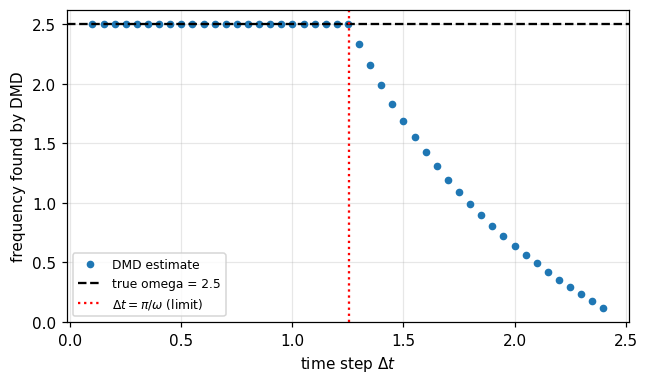

In [10]:
w_true = 2.5
dts = np.linspace(0.1, 2.4, 47)
w_est = []
for dt_s in dts:
    t = np.arange(30) * dt_s
    Vr = np.vstack([np.cos(w_true*t), np.sin(w_true*t)])
    l, G, cc = dmd(Vr, r=2)
    w_est.append(abs(np.angle(l[0])) / dt_s)               # DMD frequency estimate |arg(lambda)|/dt
w_est = np.array(w_est)

print("  dt    omega*dt   DMD frequency")
for dt_s in (0.5, 1.0, 1.2, 1.5, 2.0):
    t = np.arange(30) * dt_s
    l, _, _ = dmd(np.vstack([np.cos(w_true*t), np.sin(w_true*t)]), r=2)
    print(f" {dt_s:4.1f}   {w_true*dt_s:6.2f}      {abs(np.angle(l[0]))/dt_s:7.4f}   {'' if w_true*dt_s < np.pi else '<-- aliased (omega*dt > pi)'}")

plt.figure(figsize=(6, 3.6))
plt.plot(dts, w_est, "o", ms=4, label="DMD estimate")
plt.axhline(w_true, color="k", ls="--", label="true omega = 2.5")
plt.axvline(np.pi / w_true, color="r", ls=":", label=r"$\Delta t=\pi/\omega$ (limit)")
plt.xlabel(r"time step $\Delta t$"); plt.ylabel("frequency found by DMD"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

For $\Delta t<\pi/\omega\approx1.26$ the true frequency is recovered; beyond it DMD reports a **wrong, "folded" frequency**, with no warning. (The folded value is $|\,((\omega\Delta t+\pi)\bmod2\pi)-\pi\,|/\Delta t$.)

**Practical consequence.** Before trusting a frequency from DMD, make sure that your sampling interval is short compared with the fastest oscillation you expect: at least two samples per period, and preferably many more.

# 6. Remark 4: cost

> *We never form the $N\times N$ matrix $A$: the work is dominated by the SVD of the $N\times(n-1)$ matrix $X$.*

The SVD of an $N\times m$ matrix costs about $N\,m^2$ operations, so DMD is **linear in $N$** and, for large numbers of snapshots, **quadratic in $n$** (for the small sizes timed below the growth with $n$ lies between linear and quadratic). Let's time it.

time in seconds (rows: N, columns: n)
        n=50      n=100     n=200     n=400     
N=500   0.005     0.009     0.061     0.155     
N=1000  0.005     0.013     0.043     0.285     
N=2000  0.014     0.083     0.088     0.413     
N=4000  0.035     0.073     0.299     0.917     
N=8000  0.079     0.141     0.369     0.414     


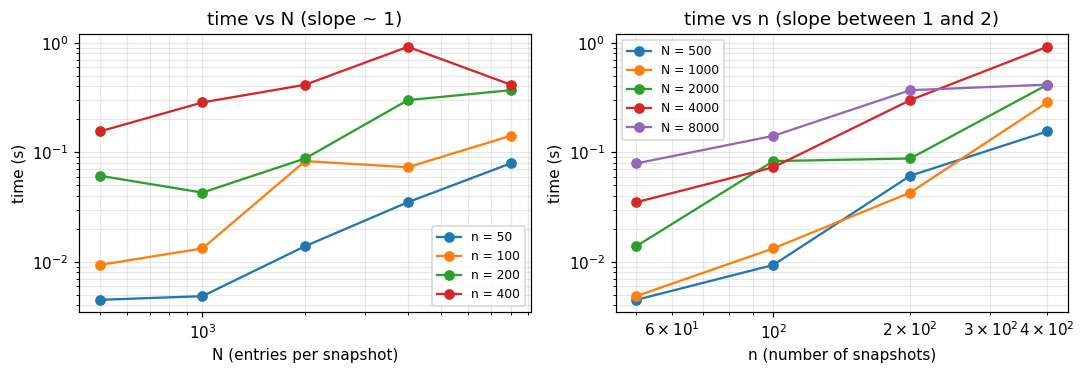

In [11]:
def time_dmd(N_, n_, r=10, repeats=2):
    V_ = np.random.default_rng(0).normal(size=(N_, n_))
    best = 1e9
    for _ in range(repeats):
        t0 = time.perf_counter(); dmd(V_, r); best = min(best, time.perf_counter() - t0)
    return best

Ns, ns = (500, 1000, 2000, 4000, 8000), (50, 100, 200, 400)
T = np.array([[time_dmd(N_, n_) for n_ in ns] for N_ in Ns])

print("time in seconds (rows: N, columns: n)")
print("        " + "".join(f"n={n_:<8d}" for n_ in ns))
for N_, row in zip(Ns, T):
    print(f"N={N_:<6d}" + "".join(f"{x:<10.3f}" for x in row))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for i, n_ in enumerate(ns): ax[0].loglog(Ns, T[:, i], "o-", label=f"n = {n_}")
ax[0].set(xlabel="N (entries per snapshot)", ylabel="time (s)", title="time vs N (slope ~ 1)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, which="both")
for i, N_ in enumerate(Ns): ax[1].loglog(ns, T[i, :], "o-", label=f"N = {N_}")
ax[1].set(xlabel="n (number of snapshots)", ylabel="time (s)", title="time vs n (slope between 1 and 2)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

Two more details of the code matter a lot for memory. First, `full_matrices=False` in the SVD call: without it NumPy returns a **square** $N\times N$ matrix $U$! Second, the propagator $A=YX^+$ would itself be $N\times N$.

In [12]:
N_, n_ = 3000, 100
X_ = np.random.default_rng(0).normal(size=(N_, n_))

t0 = time.perf_counter(); U1, s1, Vh1 = np.linalg.svd(X_, full_matrices=False); t1 = time.perf_counter() - t0
t0 = time.perf_counter(); U2, s2, Vh2 = np.linalg.svd(X_, full_matrices=True);  t2 = time.perf_counter() - t0

print(f"full_matrices=False: U {U1.shape}  {U1.nbytes/1e6:8.1f} MB   {t1:.2f} s")
print(f"full_matrices=True : U {U2.shape}  {U2.nbytes/1e6:8.1f} MB   {t2:.2f} s")
print(f"the N x N propagator A would need {N_*N_*8/1e6:.0f} MB for N = {N_}, and {20000**2*8/1e9:.1f} GB for N = 20000")

full_matrices=False: U (3000, 100)       2.4 MB   0.02 s
full_matrices=True : U (3000, 3000)      72.0 MB   0.83 s
the N x N propagator A would need 72 MB for N = 3000, and 3.2 GB for N = 20000


**Practical consequence.** For large problems (images, spectra, grids with $10^4$–$10^6$ points) the economy-size SVD and the small matrix $\tilde A$ are what make DMD feasible. If $n$ is also large, randomised SVD algorithms are used; the idea is unchanged.

---
# 7. Pitfalls of this short implementation

The 15-line function is a teaching tool. When you use it for real work, keep in mind:

* **`r` has no default.** You must choose it (Section 3).
* **Division by `lam`.** The exact modes divide by $\lambda_k$; an eigenvalue that is exactly (or nearly) zero causes a division by zero. Use the alternative $\bar\Gamma_k=\lambda_k\Gamma_k=YV\Sigma^{-1}W_k$ (same direction, no division) if you need to keep such a mode.
* **Amplitudes from the first snapshot only.** The amplitudes `c` are fitted to $v_1$ alone. If $v_1$ is noisy or not well represented by the modes, the whole prediction suffers. A common improvement is to fit the amplitudes to *all* snapshots.
* **Complex numbers.** `lam`, `Gamma`, `c` are complex in general. `predict` returns the real part, which is correct for real data (complex modes come in conjugate pairs) but would silently discard information for complex data.
* **Indexing.** `predict(..., j)` uses $j=1$ for the first snapshot, i.e. time $(j-1)\Delta t$; and $j>n$ is an extrapolation. Off-by-one errors here are common.
* **Units.** `np.log(lam)/dt` gives rates in 1/(time unit of `dt`).

# 8. Summary

| Remark | What we saw |
|---|---|
| Choosing $r$ | look for the gap in the singular values; too few modes lose dynamics, too many fit noise and can give $\lvert\lambda\rvert>1$ and exploding long-term predictions |
| Linearity | exact for linear systems; for the pendulum the model is good at the end of the data and degrades with the prediction horizon as the swing becomes nonlinear |
| Sampling | a mode with $\omega\Delta t>\pi$ is reported at a wrong, folded frequency |
| Cost | linear in $N$, between linear and quadratic in $n$ (quadratic for large $n$); never build the $N\times N$ matrix and use `full_matrices=False` |

### Check yourself
1. Why does `Vh.conj().T` appear in the code, and what is its shape?
2. A DMD run gives $\lambda=0.8\,e^{\pm1.2i}$ for $\Delta t=0.5$ s. What are the decay rate, lifetime and oscillation period?
3. You sample a 4 Hz signal every 0.2 s. Can DMD find the frequency?
4. Your singular values are $5,\ 2,\ 0.01,\ 0.01,\ 0.009,\dots$ Which $r$ would you choose?

<details><summary>Answers</summary>

1. `svd` returns $V^T$ (called `Vh`); the formulas need $V$, i.e. its (conjugate) transpose. Its shape is $(n-1)\times r$ after truncation.
2. $\mu=\ln\lambda/\Delta t$: decay rate $-\ln(0.8)/0.5\approx0.446\ \mathrm{s^{-1}}$ (lifetime $\approx2.2$ s); angular frequency $1.2/0.5=2.4$ rad/s (period $2\pi/2.4\approx2.6$ s).
3. The angular frequency is $2\pi\cdot4\approx25.1$ rad/s and $\omega\Delta t\approx5.0>\pi$, so no: the frequency is aliased (the sampling rate of 5 Hz is only 1.25 samples per period) and DMD would report 1 Hz instead of 4 Hz, with no warning.
4. $r=2$: there is a gap after the second value and the rest is a noise plateau.
</details>

In [13]:
# Numerical check of answers 2 and 3
lam_q, dt_q = 0.8*np.exp(1.2j), 0.5
mu_q = np.log(lam_q) / dt_q
print("2: decay rate", -mu_q.real, " lifetime", -1/mu_q.real, " period", 2*np.pi/mu_q.imag)
w_q, dt_q3 = 2*np.pi*4, 0.2
print("3: omega*dt =", w_q*dt_q3, "> pi =", np.pi, " -> folded frequency (Hz):",
      abs(((w_q*dt_q3 + np.pi) % (2*np.pi)) - np.pi) / dt_q3 / (2*np.pi))

2: decay rate 0.4462871026284195  lifetime 2.240710058862275  period 2.6179938779914944
3: omega*dt = 5.026548245743669 > pi = 3.141592653589793  -> folded frequency (Hz): 1.0


### More exercises
1. Extend `dmd` with an optional threshold `eps` so that `r` is chosen automatically as the number of singular values with $\sigma_k>\epsilon\,\sigma_1$. Test it on the noisy toy data of Section 3.
2. Fit the amplitudes `c` to **all** snapshots (a least-squares problem in the $r$ unknowns, using $v_j\approx\sum_kc_k\lambda_k^{\,j-1}\Gamma_k$ for every $j$) and compare the prediction errors with the first-snapshot version.
3. Use the *projected modes* $U W$ instead of the exact modes `Gamma` (and recompute the amplitudes). How different are the results on the toy data? On the pendulum?
4. In Section 4, how does the prediction error at a fixed horizon depend on the swing amplitude $\theta_0$? Plot it.
5. In Section 6, fit the measured timings to $T\propto N^a n^b$. What are $a$ and $b$ on your machine?
6. Make the toy data non-stationary: let one of the decay rates change slowly with time. What happens to DMD?

### References
* P. J. Schmid, *Dynamic mode decomposition of numerical and experimental data*, J. Fluid Mech. **656**, 5–28 (2010).
* J. H. Tu, C. W. Rowley, D. M. Luchtenburg, S. L. Brunton, J. N. Kutz, *On dynamic mode decomposition: theory and applications*, J. Comput. Dyn. **1**, 391–421 (2014). (Defines the "exact DMD" modes used here.)
* J. N. Kutz, S. L. Brunton, B. W. Brunton, J. L. Proctor, *Dynamic Mode Decomposition: Data-Driven Modeling of Complex Systems*, SIAM (2016).